In [1]:
import sys
RE_path = './RE_Solver/'
sys.path.insert(1, RE_path)

In [13]:
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *

# A Python Implementation of the Critical Electric Field

Based on https://github.com/hesslow/Eceff/

##Analytical Solution

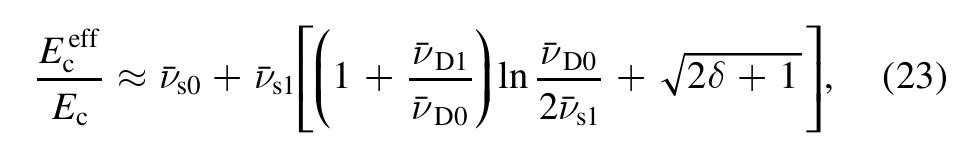

In [3]:
def calcDelta(Eceff,nuD0,nuS1,tauRadInv,phib1,phib2,pc0):
    return (nuD0/nuS1**2)*(nuD0*tauRadInv/Eceff+phib1+phib2*np.log(pc0))

def calcEceff(delta,nuS0,nuS1,nuD1,nuD0,pc0):
    return nuS0 + nuS1*( (1+nuD1/nuD0)*np.log(pc0) + np.sqrt(2*delta+1))

In [4]:
# This is probably wrong im not sure

def getEc_eff_analytic(Z, Z0, nj, T, B, element='Ne'):
    # pick the element (adapted from matlab implementation)
    if element == 'Ne':
        ln_aBar = np.array([4.7064, 4.6097, 4.5028, 4.3858, 4.2638, 4.1266, 3.9568, 3.6810, 3.1777, 3.1278])
        ln_I    = np.array([-8.2227, -8.0370, -7.8614, -7.6837, -7.4994, -7.2788, -6.9808, -6.5976, -5.8933, -5.8320])
    elif element == 'Ar':
        ln_aBar = np.array([4.5677, 4.5007, 4.4289, 4.3513, 4.2698, 4.1815, 4.0829, 3.9748,
                            3.8511, 3.7882, 3.7203, 3.6436, 3.5579, 3.4525, 3.3093, 3.0503, 2.5578, 2.5332])
        ln_I    = np.array([-7.9050, -7.7532, -7.6076, -7.4626, -7.3178, -7.1665, -7.0055, -6.8020,
                            -6.5538, -6.4647, -6.3644, -6.2465, -6.1070, -5.9219, -5.6535, -5.3213, -4.6937, -4.6598])
    else:
        raise ValueError("element must be 'Ne' or 'Ar'")

    # ensure arrays
    Z = np.atleast_1d(Z).astype(int)
    Z0 = np.atleast_1d(Z0).astype(int)
    nj = np.atleast_1d(nj).astype(float)

    # constants
    ne_free = np.sum(Z0 * nj)
    ntot = np.sum(Z * nj)
    Zeff = np.sum((Z0**2 * nj)) / ne_free
    Zfulleff = np.sum((Z**2 * nj)) / ne_free
    lnLStar = 14.6 + 0.5 * np.log(T / (ne_free / 1e20))
    Ne_bound = Z - Z0

    nuD0 = (1 + Zeff) - (2.0/3.0) * np.sum(Ne_bound**2 * nj) / ne_free / lnLStar
    nuD1 = Zfulleff / lnLStar
    nuS0 = 1.0
    nuS1 = (1.0 + 3.0 * np.sum(Ne_bound * nj) / ne_free) / (2.0 * lnLStar)

    
    for i in range(1, Z.shape[0]):
        z0i = Z0[i]
        nuD0 += (Z[i]**2 - Z0[i]**2) * ln_aBar[z0i] * (nj[i] / ne_free) / lnLStar
        nuS0 += Ne_bound[i] * (-ln_I[z0i] - 1.0) * (nj[i] / ne_free) / lnLStar

    #  bremsstrahlung terms
    ALPHA = 1.0 / 137.036
    tauRadInv = B**2 / (ne_free/1e20) / (15.44 * lnLStar)
    bremsprefactor = ALPHA * Zfulleff / lnLStar
    phib1 = bremsprefactor * 0.35
    phib2 = bremsprefactor * 0.20

    pc0 = nuD0 / (2.0 * nuS1)

    
    Ectot = ntot/ne_free # in units of E_c
    Eceff0 = Ectot
    delta0 = calcDelta(Eceff0,nuD0,nuS1,tauRadInv,phib1,phib2,pc0)
    delta1 = calcDelta(calcEceff(delta0,
                                nuS0,nuS1,nuD1,nuD0,pc0),
                       nuD0,nuS1,tauRadInv,phib1,phib2,pc0)

    EceffOverEctot = calcEceff(delta1,nuS0,nuS1,nuD1,nuD0,pc0)/Ectot
    Ectot =  ntot *  const.e**3  * lnLStar /(4 * np.pi * const.epsilon_0**2 * const.m_e * const.c**2)

    return Ectot * EceffOverEctot, Ectot
#Ectot * EceffOverEctot, Ectot
''' Ectot = ntot/ne_free # in units of E_c
    Eceff0 = Ectot
    delta0 = calcDelta(Eceff0,nuD0,nuS1,tauRadInv,phib1,phib2,pc0)
    delta1 = calcDelta(calcEceff(delta0,
                                nuS0,nuS1,nuD1,nuD0,pc0),
                       nuD0,nuS1,tauRadInv,phib1,phib2,pc0)

    EceffOverEctot = calcEceff(delta1,nuS0,nuS1,nuD1,nuD0,pc0)/Ectot
    Ectot =  ntot *  const.e**3  * lnLStar /(4 * np.pi * const.epsilon_0**2 * const.m_e * const.c**2);'''


' Ectot = ntot/ne_free # in units of E_c\n    Eceff0 = Ectot\n    delta0 = calcDelta(Eceff0,nuD0,nuS1,tauRadInv,phib1,phib2,pc0)\n    delta1 = calcDelta(calcEceff(delta0,\n                                nuS0,nuS1,nuD1,nuD0,pc0),\n                       nuD0,nuS1,tauRadInv,phib1,phib2,pc0)\n\n    EceffOverEctot = calcEceff(delta1,nuS0,nuS1,nuD1,nuD0,pc0)/Ectot\n    Ectot =  ntot *  const.e**3  * lnLStar /(4 * np.pi * const.epsilon_0**2 * const.m_e * const.c**2);'

In [5]:
# example for singly-ionized Ar (Ar1+)
Z = np.array([1, 18])
Z0 = np.array([1, 2])
nj = np.array([1e20, 1e20])
T = 10.0
B = 0

Eceff_analytic, Ectot = getEc_eff_analytic(Z, Z0, nj, T, B, element='Ar')
print('Eceff analytic [V/m] =', Eceff_analytic)
print('Ectot [V/m] =', Ectot)


Eceff analytic [V/m] = 1.7333541387935076
Ectot [V/m] = 1.4728122761596514


In [6]:
### Functions ####

def calcDelta(Eceff,nuD0,nuS1,tauRadInv,phib1,phib2,pc0):
    return (nuD0/nuS1**2)*(nuD0*tauRadInv/Eceff+phib1+phib2*np.log(pc0))

def calcEceff(delta,nuS0,nuS1,nuD1,nuD0,pc0):
    return nuS0 + nuS1*( (1+nuD1/nuD0)*np.log(pc0) + np.sqrt(2*delta+1))

def getEc_eff_NE(Z,Z0,nj,T,B):
    
    # Returns the effective critical electric field and Ectot with Ne impurities in V/m
    # INPUTS:
    #       Z   : atomic number of each ion species
    #       Z0  : net charge of plasma for each ion species
    #       nj  : density of each ion species [m^(-3)]
    #       Z, Z0 and nj must be arrays of length nSpecies
    #       T   : temperature [eV]  (for calculation of the Coulomb logarithm)
    #       B   : magnetic field [T]
   
    # Constants for Ne
    ln_aBar_Ne = np.array([4.7064, 4.6097, 4.5028, 4.3858, 4.2638, 4.1266, 3.9568, 3.6810, 3.1777, 3.1278])
    ln_I_Ne = np.array([-8.2227, -8.0370, -7.8614, -7.6837, -7.4994, -7.2788, -6.9808, -6.5976, -5.8933, -5.8320])
    
    ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
    ntot = np.sum(Z * nj) # Bound + Free electron density, per cubic m 
    Zeff = np.sum((Z0**2 * nj))/ne_free # Effective Ionization
    Zfulleff = np.sum(Z**2 * nj)/ne_free 
    lnLStar = 14.6 + 0.5 * np.log(T / (ne_free/1e20)) # Coul. Log
    Ne = Z - Z0 # No. of bound electrons

    ## calculate the constants nuD0, nuD1, nuS0, nuS1
    nuD0 = (1 + Zeff) - 2/3 * np.sum(Ne**2 * nj)/ne_free /lnLStar
    nuD1 = Zfulleff/lnLStar
    nuS0 = 1
    nuS1 = (1 + 3 * np.sum(Ne * nj)/ne_free)/(2*lnLStar)
    for i in range(1,Z.shape[0]):
        nuD0 = nuD0 + (Z[i]**2 - Z0[i]**2) * ln_aBar_Ne[Z0[i]] * (nj[i]/ne_free) / lnLStar
        nuS0 = nuS0 + Ne[i] * (-ln_I_Ne[Z0[i]]-1) * (nj[i]/ne_free) / lnLStar

    #### Radiation Terms ####

    # synchrotron radiation term
    tauRadInv =  B**2/(ne_free/1e20)/(15.44*lnLStar);

    # bremsstrahlung term
    ALPHA = 1/137.036;
    bremsprefactor = ALPHA * Zfulleff/lnLStar;
    phib1 = bremsprefactor*0.35;
    phib2 = bremsprefactor*0.20;

    pc0 = nuD0/(2*nuS1);

    Ectot = ntot/ne_free # in units of E_c
    Eceff0 = Ectot
    delta0 = calcDelta(Eceff0,nuD0,nuS1,tauRadInv,phib1,phib2,pc0)
    delta1 = calcDelta(calcEceff(delta0,
                                nuS0,nuS1,nuD1,nuD0,pc0),
                       nuD0,nuS1,tauRadInv,phib1,phib2,pc0)

    EceffOverEctot = calcEceff(delta1,nuS0,nuS1,nuD1,nuD0,pc0)/Ectot
    Ectot =  ntot *  const.e**3  * lnLStar /(4 * np.pi * const.epsilon_0**2 * const.m_e * const.c**2);
    
    return Ectot * EceffOverEctot, Ectot


In [7]:
## Example Usage  ##

# Inputs
Z = np.array([1,10]); # Max. Ionization, the first entry is for fully ionized deuterium, second for partially ionized Ne
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10;
B = 0; 


Ec_eff = getEc_eff_NE(Z,Z0,nj,T,B) # [V/m] Call the function

print('Eceff [V/m] = %1.3f\n'%(Ec_eff[0]))
print('Ectot [V/m] = %1.3f\n'%(Ec_eff[1]))


Eceff [V/m] = 0.876

Ectot [V/m] = 0.864



<>:22: SyntaxWarning: invalid escape sequence '\,'
<>:23: SyntaxWarning: invalid escape sequence '\,'
<>:22: SyntaxWarning: invalid escape sequence '\,'
<>:23: SyntaxWarning: invalid escape sequence '\,'
C:\Users\grace\AppData\Local\Temp\ipykernel_24872\3473143337.py:22: SyntaxWarning: invalid escape sequence '\,'
  plt.xlabel('$n_Z \, [m^{-3}]$ ')
C:\Users\grace\AppData\Local\Temp\ipykernel_24872\3473143337.py:23: SyntaxWarning: invalid escape sequence '\,'
  plt.ylabel('$E_c^{eff}/E_c^{tot} \, [-]$ ')
C:\Users\grace\AppData\Local\Temp\ipykernel_24872\3473143337.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


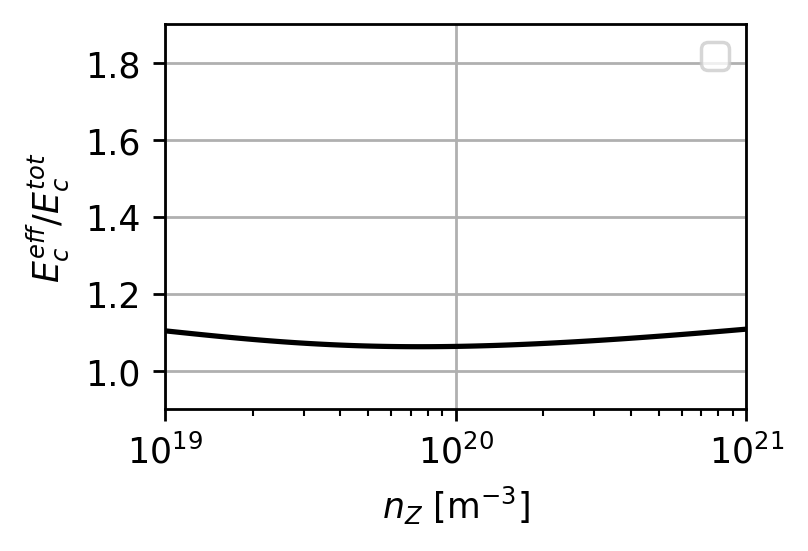

In [8]:
# Calculating Eeff with Ne impurities - vary nz

# Inputs
nz = np.logspace(19,21,100)
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,2]); # Ionization Level
T = 10;
B = 0; 

Ec_eff = np.zeros_like(nz)
for ii in range(nz.shape[0]):
    nj = np.array([1e20,nz[ii]]); # Density
    out = getEc_eff_NE(Z,Z0,nj,T,B) # [Ec_eff, Ec_tot] in [V/m]
    Ec_eff[ii] = out[0]/out[1] # Ec_eff / Ec_tot


# Plot 
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=250)
plt.plot(nz,Ec_eff,'-k')
plt.xscale('log')
plt.ylim([0.9,1.9])
plt.xlabel('$n_Z \, [m^{-3}]$ ')
plt.ylabel('$E_c^{eff}/E_c^{tot} \, [-]$ ')
plt.grid()
plt.xlim([1e19,1e21])

plt.xlabel(r'$n_Z$ [m$^{-3}$]')
plt.ylabel(r'$E_c^{eff}/E_c^{tot}$')
plt.legend()
plt.grid(True)
plt.show()




In [9]:
def getEc_eff_AR(Z,Z0,nj,T,B):
    
    # Returns the effective critical electric field and Ectot with Ne impurities in V/m
    # INPUTS:
    #       Z   : atomic number of each ion species
    #       Z0  : net charge of plasma for each ion species
    #       nj  : density of each ion species [m^(-3)]
    #       Z, Z0 and nj must be arrays of length nSpecies
    #       T   : temperature [eV]  (for calculation of the Coulomb logarithm)
    #       B   : magnetic field [T]
   
    # Constants for Ne
    ln_aBar_Ar = np.array([4.5677, 4.5007, 4.4289, 4.3513, 4.2698, 4.1815, 4.0829, 3.9748,
        3.8511, 3.7882, 3.7203, 3.6436, 3.5579, 3.4525, 3.3093, 3.0503, 2.5578, 2.5332])
    
    ln_I_Ar = np.array([-7.9050, -7.7532, -7.6076, -7.4626, -7.3178, -7.1665, -7.0055, -6.8020,
    -6.5538, -6.4647, -6.3644, -6.2465, -6.1070, -5.9219, -5.6535, -5.3213, -4.6937, -4.6598])
    
    ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
    ntot = np.sum(Z * nj) # Bound + Free electron density, per cubic m 
    Zeff = np.sum((Z0**2 * nj))/ne_free # Effective Ionization
    Zfulleff = np.sum(Z**2 * nj)/ne_free 
    lnLStar = 14.6 + 0.5 * np.log(T / (ne_free/1e20)) # Coul. Log
    Ne = Z - Z0 # No. of bound electrons

    ## calculate the constants nuD0, nuD1, nuS0, nuS1
    nuD0 = (1 + Zeff) - 2/3 * np.sum(Ne**2 * nj)/ne_free /lnLStar
    nuD1 = Zfulleff/lnLStar
    nuS0 = 1
    nuS1 = (1 + 3 * np.sum(Ne * nj)/ne_free)/(2*lnLStar)
    for i in range(1,Z.shape[0]):
        nuD0 = nuD0 + (Z[i]**2 - Z0[i]**2) * ln_aBar_Ar[Z0[i]] * (nj[i]/ne_free) / lnLStar
        nuS0 = nuS0 + Ne[i] * (-ln_I_Ar[Z0[i]]-1) * (nj[i]/ne_free) / lnLStar

    #### Radiation Terms ####

    # synchrotron radiation term
    tauRadInv =  B**2/(ne_free/1e20)/(15.44*lnLStar);

    # bremsstrahlung term
    ALPHA = 1/137.036;
    bremsprefactor = ALPHA * Zfulleff/lnLStar;
    phib1 = bremsprefactor*0.35;
    phib2 = bremsprefactor*0.20;

    pc0 = nuD0/(2*nuS1);

    Ectot = ntot/ne_free # in units of E_c
    Eceff0 = Ectot
    delta0 = calcDelta(Eceff0,nuD0,nuS1,tauRadInv,phib1,phib2,pc0)
    delta1 = calcDelta(calcEceff(delta0,
                                nuS0,nuS1,nuD1,nuD0,pc0),
                       nuD0,nuS1,tauRadInv,phib1,phib2,pc0)

    EceffOverEctot = calcEceff(delta1,nuS0,nuS1,nuD1,nuD0,pc0)/Ectot
    Ectot =  ntot *  const.e**3  * lnLStar /(4 * np.pi * const.epsilon_0**2 * const.m_e * const.c**2);
    
    return Ectot * EceffOverEctot, Ectot


Eceff [V/m] = 0.861

Ectot [V/m] = 0.864



<>:37: SyntaxWarning: invalid escape sequence '\,'
<>:38: SyntaxWarning: invalid escape sequence '\,'
<>:37: SyntaxWarning: invalid escape sequence '\,'
<>:38: SyntaxWarning: invalid escape sequence '\,'
C:\Users\grace\AppData\Local\Temp\ipykernel_24872\2160625643.py:37: SyntaxWarning: invalid escape sequence '\,'
  plt.xlabel('$n_Z \, [m^{-3}]$ ')
C:\Users\grace\AppData\Local\Temp\ipykernel_24872\2160625643.py:38: SyntaxWarning: invalid escape sequence '\,'
  plt.ylabel('$E_c^{eff}/E_c^{tot} \, [-]$ ')


(1e+19, 1e+21)

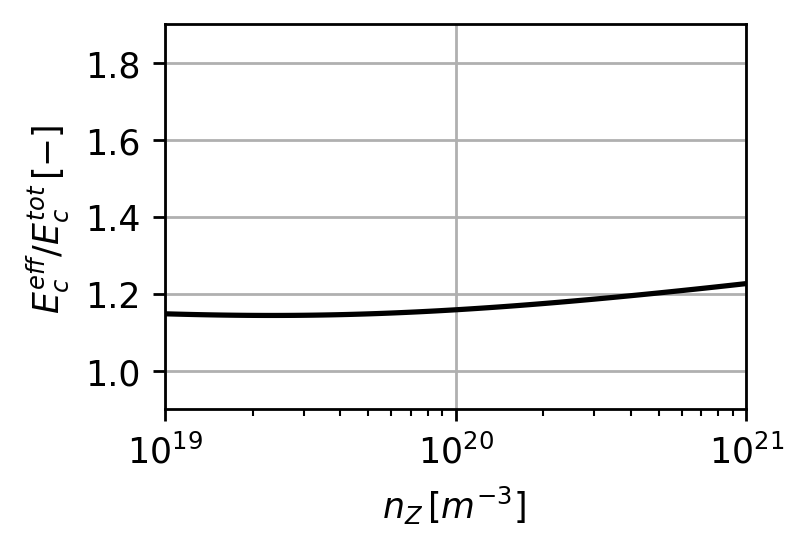

In [10]:
## Example Usage ##

# Inputs
Z = np.array([1,10]); # Max. Ionization, the first entry is for fully ionized deuterium, second for partially ionized Ne
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10;
B = 0; 


Ec_eff = getEc_eff_AR(Z,Z0,nj,T,B) # [V/m] Call the function

print('Eceff [V/m] = %1.3f\n'%(Ec_eff[0]))
print('Ectot [V/m] = %1.3f\n'%(Ec_eff[1]))

# Calculating Eeff with Ar impurities - vary nz

# Inputs
nz = np.logspace(19,21,100)
Z = np.array([1,17]); # Max. Ionization
Z0 = np.array([1,2]); # Ionization Level
T = 10;
B = 0; 

Ec_eff = np.zeros_like(nz)
for ii in range(nz.shape[0]):
    nj = np.array([1e20,nz[ii]]); # Density
    out = getEc_eff_AR(Z,Z0,nj,T,B) # [Ec_eff, Ec_tot] in [V/m]
    Ec_eff[ii] = out[0]/out[1] # Ec_eff / Ec_tot

    
# Plot #
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=250)
plt.plot(nz,Ec_eff,'-k')
plt.xscale('log')
plt.ylim([0.9,1.9])
plt.xlabel('$n_Z \, [m^{-3}]$ ')
plt.ylabel('$E_c^{eff}/E_c^{tot} \, [-]$ ')
plt.grid()
plt.xlim([1e19,1e21])

### Recreate the following figures and comapre the implementation

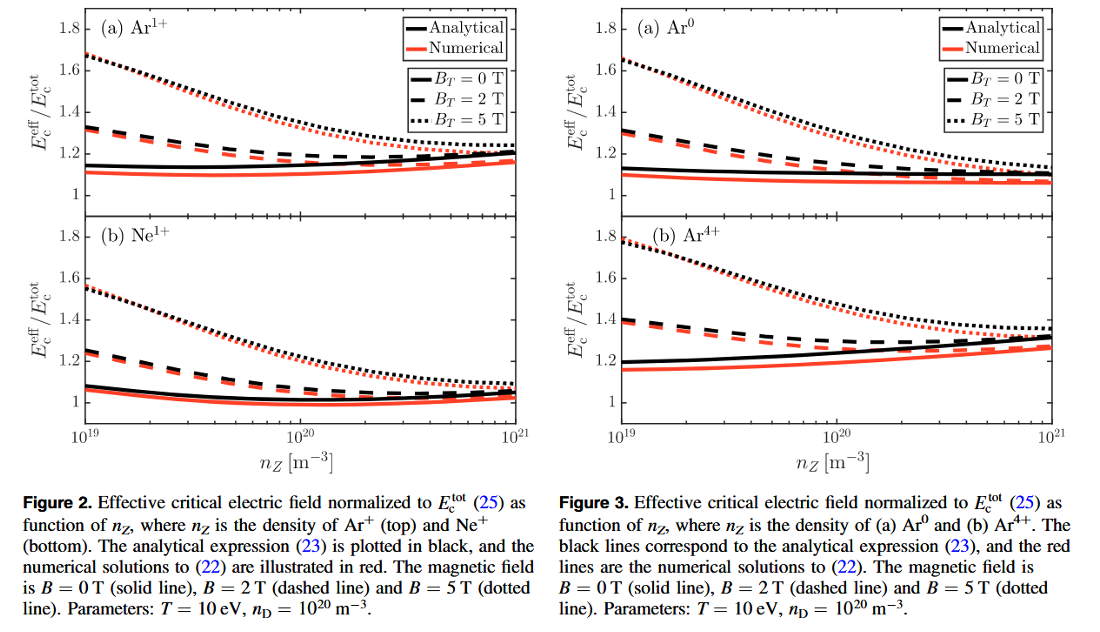

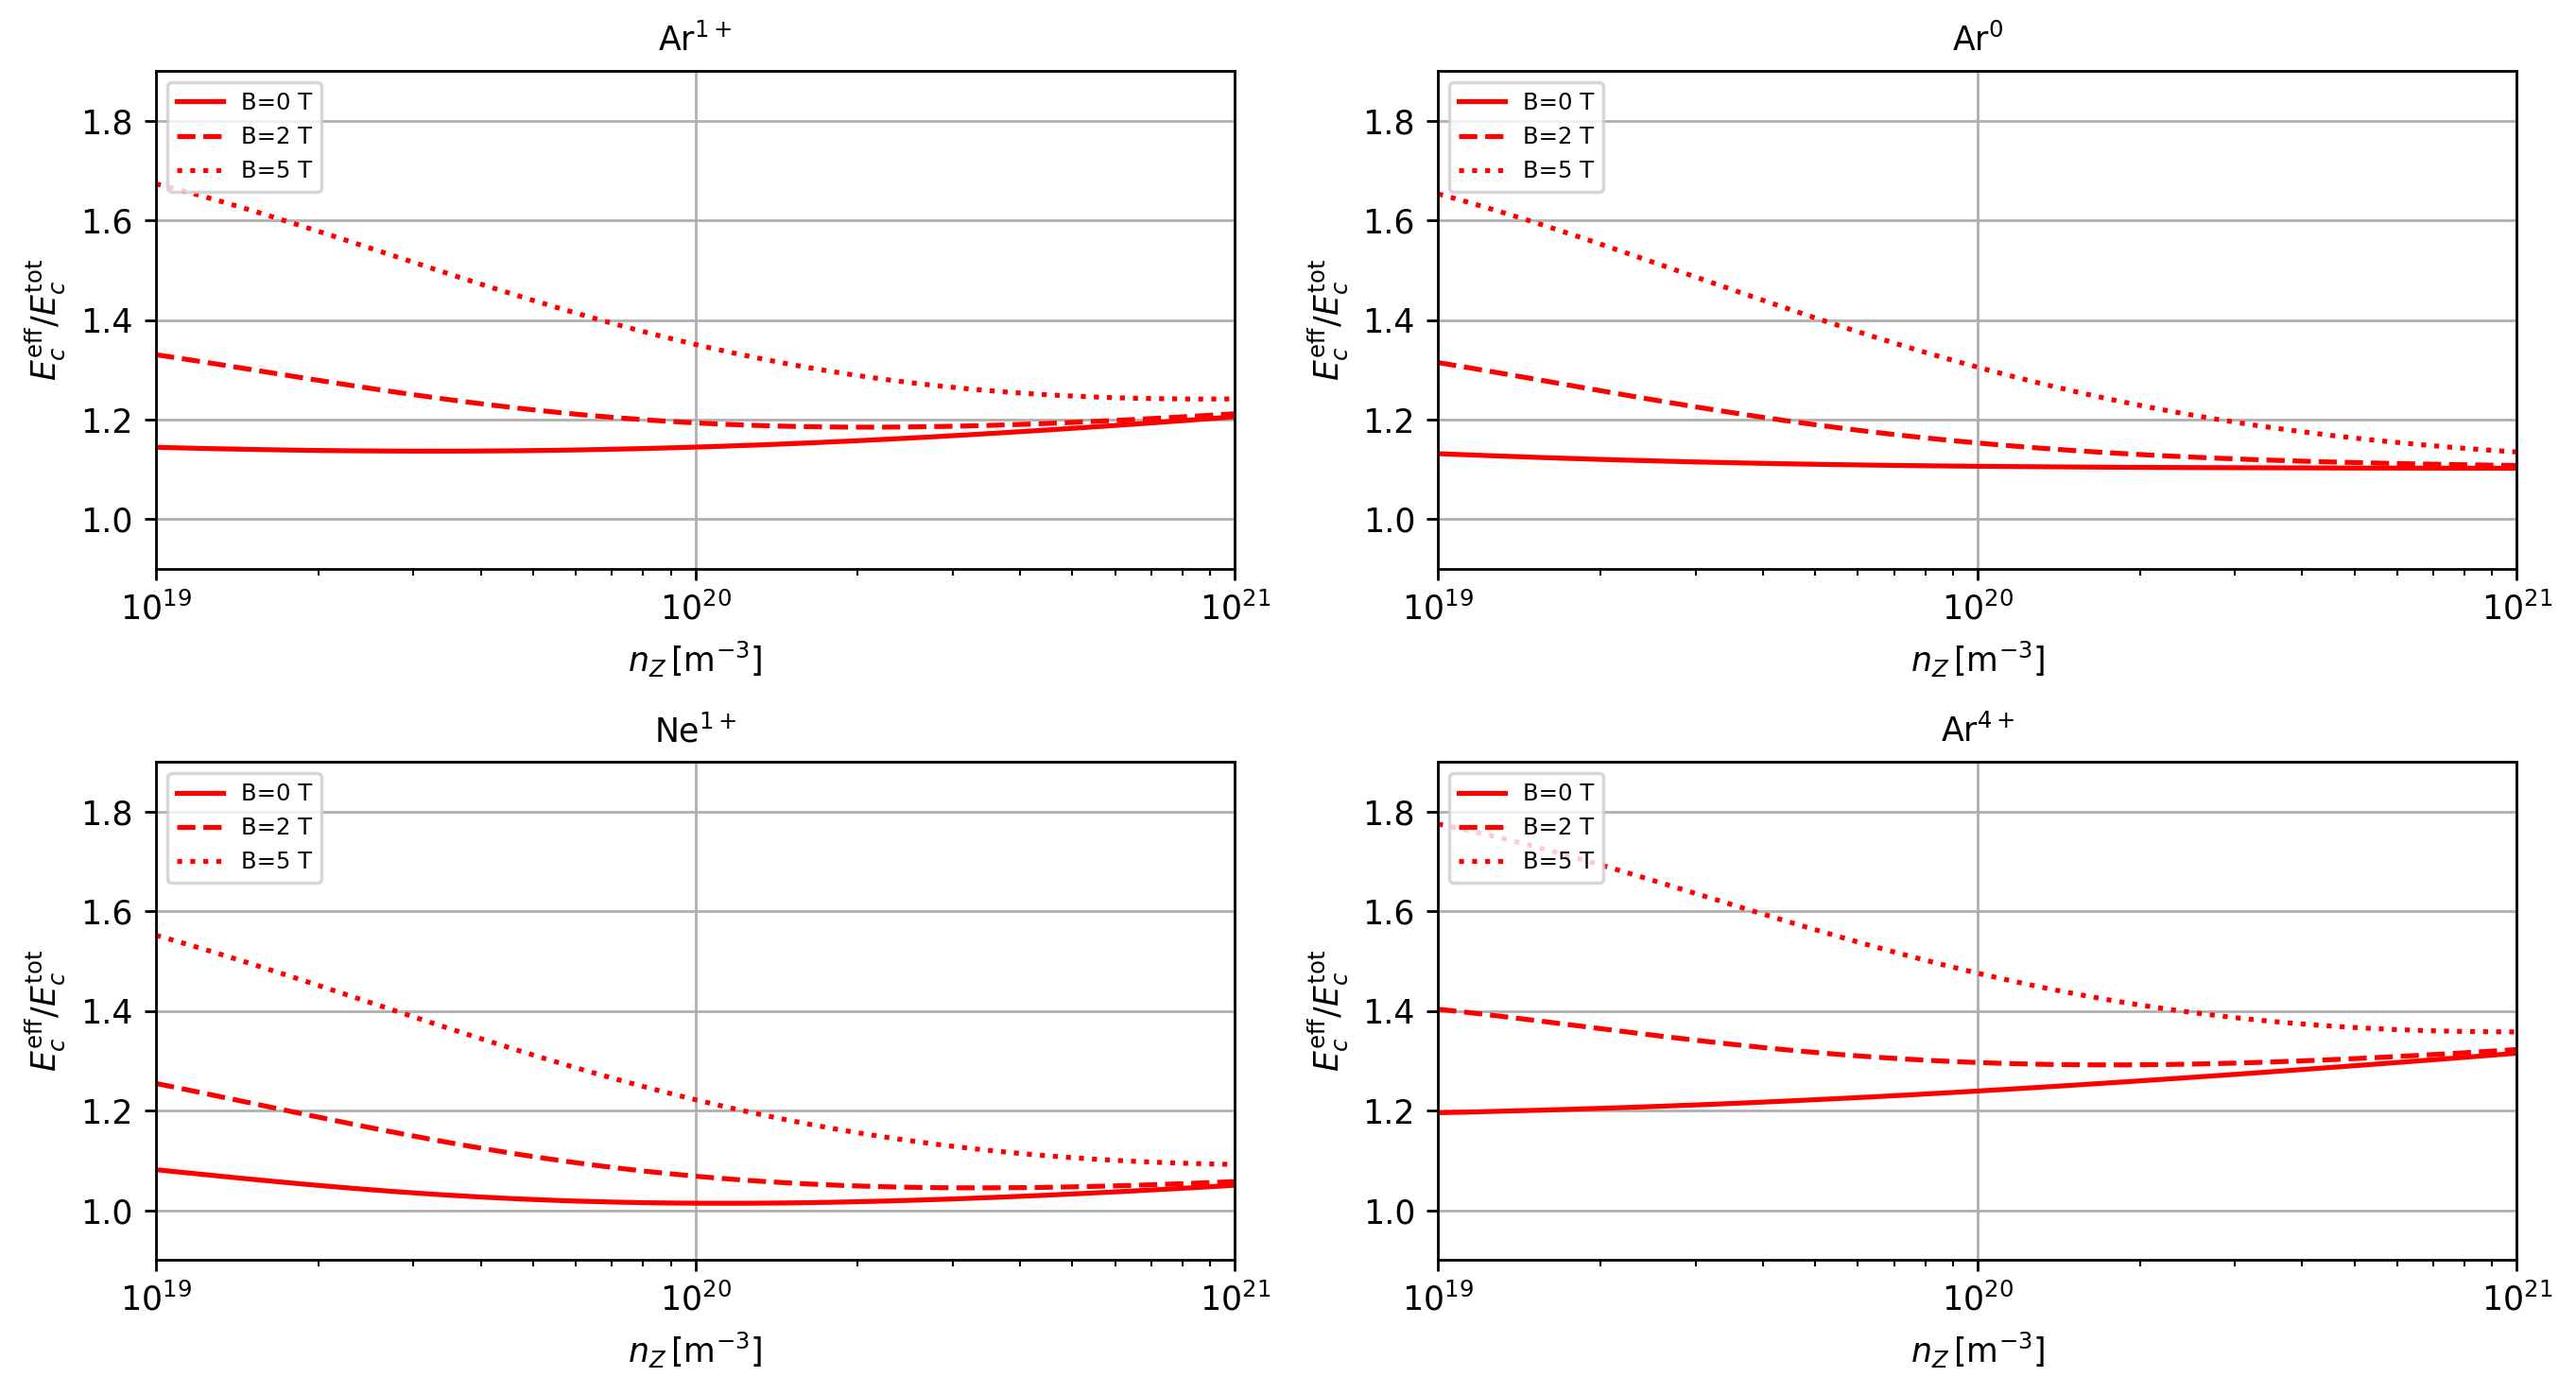

"\nEc_eff_ana = np.zeros_like(nz)\n        for i, nzi in enumerate(nz):\n            nj = np.array([1e20, nzi])\n            out = getEc_eff_analytic(Z, Z0, nj, T, Bi, element=element)\n            Ec_eff_ana[i] = out[0] / out[1]\n        ax.plot(nz, Ec_eff_ana, linestyle=line, color='k')\n"

In [11]:
# helper plotting function 
def plot_Eceff(ax, get_func, Z, Z0, T=10, Bs=[0,2,5], label='', element='Ne'):
   
    nz = np.logspace(19, 21, 100)
    lines = ['solid', 'dashed', 'dotted']
    
    for Bi, line in zip(Bs, lines):
        
        
        Ec_eff = np.zeros_like(nz)
        for i, nzi in enumerate(nz):
            nj = np.array([1e20, nzi])
            out = get_func(Z, Z0, nj, T, Bi)
            Ec_eff[i] = out[0] / out[1]
        ax.plot(nz, Ec_eff, linestyle=line, color = 'r', label=f'B={Bi} T')

        

    ax.set_xscale('log')
    ax.set_xlim([1e19, 1e21])
    ax.set_ylim([0.9, 1.9])
    ax.grid(True)
    ax.set_xlabel(r'$n_Z \, [\mathrm{m^{-3}}]$')
    ax.set_ylabel(r'$E_c^{\mathrm{eff}} / E_c^{\mathrm{tot}}$')
    ax.set_title(label, fontsize=10)
    ax.legend(fontsize=7, loc='upper left')

fig, axs = plt.subplots(2, 2, figsize=(11, 6), dpi=250)
plt.subplots_adjust(wspace=0.3, hspace=0.35)

#  Ar1+

Z, Z0 = np.array([1, 18]), np.array([1, 1])
plot_Eceff(axs[0, 0], getEc_eff_AR, Z, Z0, label='Ar$^{1+}$')

#  Ar0
Z, Z0 = np.array([1, 18]), np.array([1, 0])
plot_Eceff(axs[0, 1], getEc_eff_AR, Z, Z0, label='Ar$^{0}$')

#  Ne1+
Z, Z0 = np.array([1, 10]), np.array([1, 1])
plot_Eceff(axs[1, 0], getEc_eff_NE, Z, Z0, label='Ne$^{1+}$')

#  Ar4+
Z, Z0 = np.array([1, 18]), np.array([1, 4])
plot_Eceff(axs[1, 1], getEc_eff_AR, Z, Z0, label='Ar$^{4+}$')

plt.tight_layout()
plt.show()

'''
Ec_eff_ana = np.zeros_like(nz)
        for i, nzi in enumerate(nz):
            nj = np.array([1e20, nzi])
            out = getEc_eff_analytic(Z, Z0, nj, T, Bi, element=element)
            Ec_eff_ana[i] = out[0] / out[1]
        ax.plot(nz, Ec_eff_ana, linestyle=line, color='k')
'''


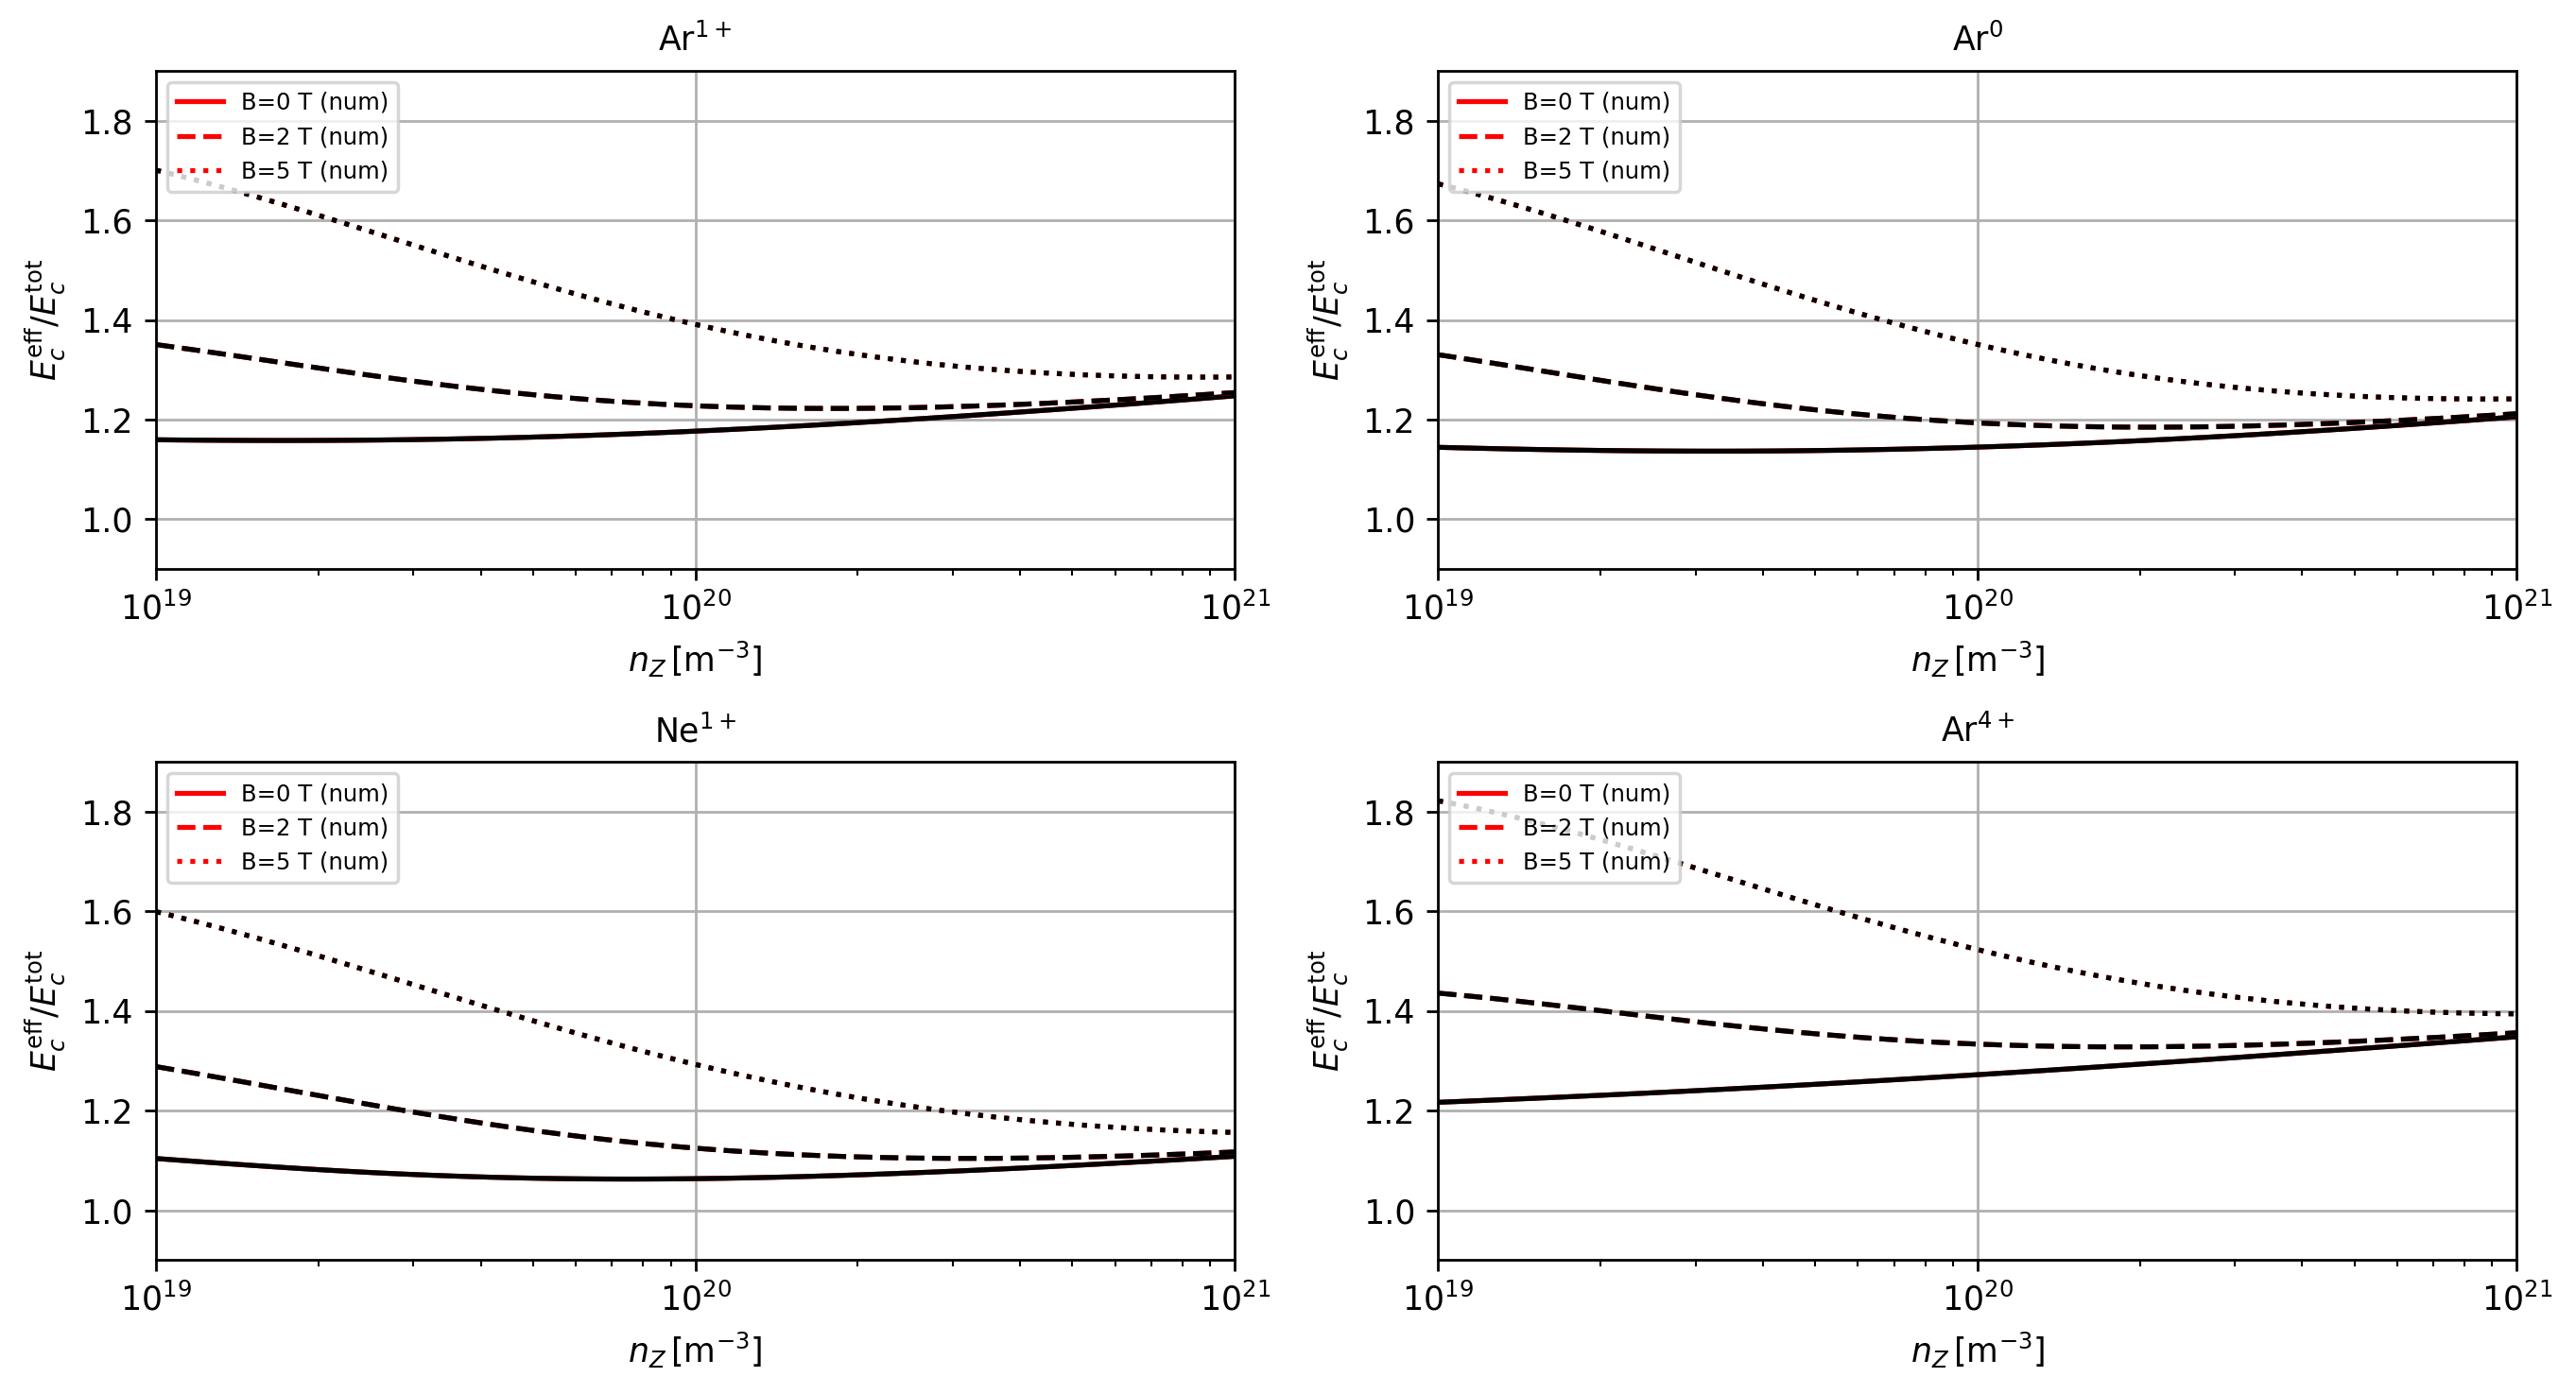

In [12]:
def plot_Eceff(ax, get_func, Z, Z0, T=10, Bs=[0,2,5], label='', element='Ne'):
   
    nz = np.logspace(19, 21, 100)
    lines = ['solid', 'dashed', 'dotted']

    for Bi, line in zip(Bs, lines):
        # ---- numerical (red) ----
        Ec_eff_num = np.zeros_like(nz)
        for i, nzi in enumerate(nz):
            nj = np.array([1e20, nzi])
            out = get_func(Z, Z0, nj, T, Bi)
            Ec_eff_num[i] = out[0] / out[1]
        ax.plot(nz, Ec_eff_num, linestyle=line, color='r', label=f'B={Bi} T (num)')

        # ---- analytical (black) ----
        Ec_eff_ana = np.zeros_like(nz)
        for i, nzi in enumerate(nz):
            nj = np.array([1e20, nzi])
            out = getEc_eff_analytic(Z, Z0, nj, T, Bi, element=element)
            Ec_eff_ana[i] = out[0] / out[1]
        ax.plot(nz, Ec_eff_ana, linestyle=line, color='k')

    # ---- formatting ----
    ax.set_xscale('log')
    ax.set_xlim([1e19, 1e21])
    ax.set_ylim([0.9, 1.9])
    ax.grid(True)
    ax.set_xlabel(r'$n_Z \, [\mathrm{m^{-3}}]$')
    ax.set_ylabel(r'$E_c^{\mathrm{eff}} / E_c^{\mathrm{tot}}$')
    ax.set_title(label, fontsize=10)
    ax.legend(fontsize=7, loc='upper left')


# --- main 2x2 plot ---
fig, axs = plt.subplots(2, 2, figsize=(11, 6), dpi=250)
plt.subplots_adjust(wspace=0.3, hspace=0.35)

# (a) Ar1+
Z, Z0 = np.array([1, 18]), np.array([1, 2])
plot_Eceff(axs[0, 0], getEc_eff_AR, Z, Z0, label='Ar$^{1+}$', element='Ar')

# (b) Ar0
Z, Z0 = np.array([1, 18]), np.array([1, 1])
plot_Eceff(axs[0, 1], getEc_eff_AR, Z, Z0, label='Ar$^{0}$', element='Ar')

# (c) Ne1+
Z, Z0 = np.array([1, 10]), np.array([1, 2])
plot_Eceff(axs[1, 0], getEc_eff_NE, Z, Z0, label='Ne$^{1+}$', element='Ne')

# (d) Ar4+
Z, Z0 = np.array([1, 18]), np.array([1, 5])
plot_Eceff(axs[1, 1], getEc_eff_AR, Z, Z0, label='Ar$^{4+}$', element='Ar')

plt.tight_layout()
plt.show()


### Ec_eff vs. neon density (T = 10 eV, B = 0 T), for Z = (1, 3, 5, 7, 9)

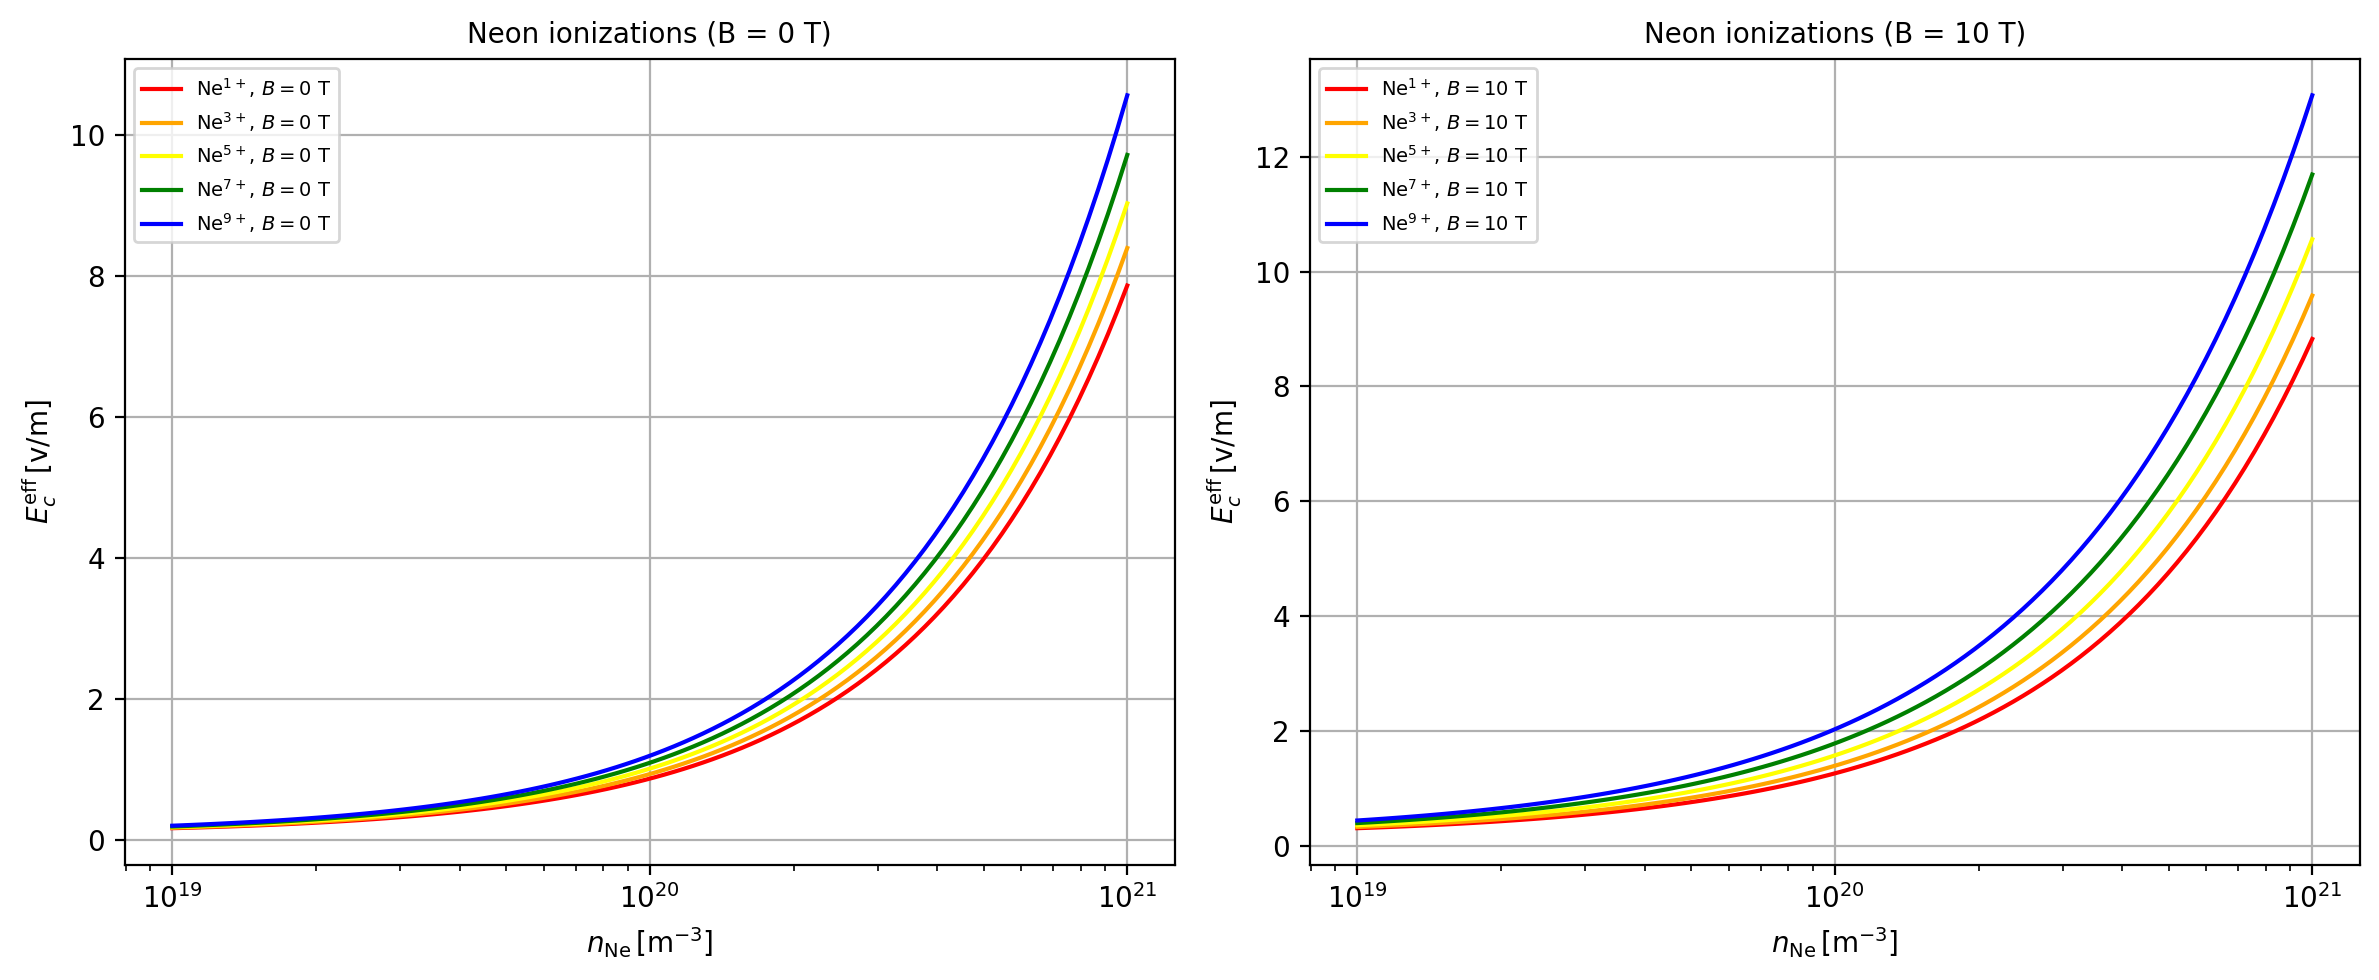

In [26]:

def plot_Eceff(ax, get_func, T=10, Bs=0, label='', element='Ne'):
    Z0_values = [1, 3, 5, 7, 9]
    colors = ['red', 'orange', 'yellow', 'green', 'blue']
    nz = np.logspace(19, 21, 100)  # Neon density range

    for Z0_neon, color in zip(Z0_values, colors):
        Ec_eff = np.zeros_like(nz)

        Z_vec  = np.array([1, 10])             
        Z0_vec = np.array([1, Z0_neon])        

        for i, nzi in enumerate(nz):
            nj = np.array([1e20, nzi])  
            Eceff, Ectot = get_func(Z_vec, Z0_vec, nj, T=T, B=Bs, element=element)
            Ec_eff[i] = Eceff   # not normalized

        ax.plot(
            nz, Ec_eff,
            color=color,
            label=fr'Ne$^{{{Z0_neon}+}}$, $B={Bs}$ T'
        )

    ax.set_xscale('log')
    #ax.set_xlim([1e19, 1e21])
    #ax.set_ylim([0.9, 1.9])
    ax.grid(True)
    ax.set_xlabel(r'$n_{\mathrm{Ne}} \, [\mathrm{m^{-3}}]$')
    ax.set_ylabel(r'$E_c^{\mathrm{eff}} \, [\mathrm{v/m}]$')
    ax.set_title(label, fontsize=10)
    ax.legend(fontsize=7, loc='upper left')

fig, axs = plt.subplots(1, 2, figsize=(12, 5), dpi=200)

plot_Eceff(axs[0], getEc_eff, T=10, Bs=0,  label='Neon ionizations (B = 0 T)',  element='Ne')
plot_Eceff(axs[1], getEc_eff, T=10, Bs=10, label='Neon ionizations (B = 10 T)', element='Ne')

plt.tight_layout()
plt.show()
